# Trying the dynamic problem with PS-GKS...

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
#!/usr/bin/env python
"""
Demo for Emoji dynamic tomography test problem
--------------------------------------------------------------------------
Created in 2023 for TRIPs-Py library
"""
__authors__ = "Mirjeta Pasha and Silvia Gazzola"
__affiliations__ = 'MIT and Tufts University, University of Bath'
__copyright__ = "Copyright 2023, TRIPs-Py library"
__license__ = "Apache"
__version__ = "1.0"
__email__ = "mpasha@mit.edu; mirjeta.pasha1@gmail.com; sg968@bath.ac.uk;"

In [3]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from scipy.linalg import fractional_matrix_power
from numpy import array, diag, dot, maximum, empty, repeat, ones, sum
from numpy.linalg import inv
import scipy as sp
import scipy.stats as sps
import scipy.io as spio
import astra
from venv import create
import pylops
from scipy import sparse
from scipy.ndimage import convolve
import scipy.special as spe
import requests
import h5py
from trips.utilities.io import *
from trips.utilities.operators import *
from trips.utilities.helpers import *
from trips.solvers.GKS import *
from trips.solvers.MMGKS import *


import sys
sys.path.append("../")



# # Go three directories up
# current_dir = os.path.dirname(os.getcwd())
# three_dirs_up = os.path.abspath(os.path.join(current_dir, '..', '..'))
# sys.path.append(three_dirs_up)


# from msolver import MM2019GKS, IASGKS, VanillaGKS, MMGKS, MM3GKS, MM2GKS, MMXGKS
# from fsolver import IASFGK, MM2019FGK, MMFGK, MM3FGK, MMXFGK # VanillaFK
# from pgkbsolver import MM2019GKB, IASGKB, MMGKB, MM3GKB, MMXGKB
# from f2019solver import MM2019FGK2019, IASFGK2019

# from pinv import CGWeightedNeumann2DPinvOperatorGP

/home/jlindbloom/miniconda3/envs/jlinops/lib/python3.11/site-packages/cupyx/jit/_interface.py:173: FutureWarning: cupyx.jit.rawkernel is experimental. The interface can change in the future.
  cupy._util.experimental('cupyx.jit.rawkernel')


In [ ]:
(F, d, Aseq, B, nx, ny, nt) = generate_emoji(dataset = 30)

data already downloaded.


In [ ]:
# Compute a solution by GKS
# Define a derivative operator as a regularization operator
# L = spatial_derivative_operator(nx, ny, nt)
time_step = 5
A1 = Aseq[time_step]
b1 = B[time_step]
L = gen_first_derivative_operator_2D(nx, ny)
data_vec = d.reshape((-1,1))
# Use GKS to compute an approximate solution
(x_mmgks_1, info_mmgks_1) = MMGKS(A1, b1.reshape((-1,1)), L, pnorm = 2, qnorm = 1, projection_dim = 1, n_iter = 100, regparam = 'gcv', x_true = None, epsilon = 0.001)

running MMGKS...:  62%|██████▏   | 62/100 [00:03<00:03, 10.19it/s] 

(-0.5, 127.5, 127.5, -0.5)

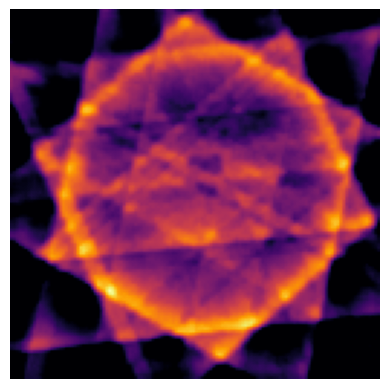

In [ ]:
x_mmgks_1[x_mmgks_1<0] = 0
plt.imshow(x_mmgks_1.reshape((nx, ny)))
plt.set_cmap('inferno')
plt.axis('off')

In [ ]:
xx = list(range(nt))
L = spatial_derivative_operator(nx, ny, 1)
for i in range(nt):
    b_vec = B[i].reshape((-1,1))
    (x_static_mmgks, info_mmgks) = MMGKS(Aseq[i], b_vec, L, pnorm=2, qnorm= 0.1, projection_dim=1, n_iter = 100, regparam= 'gcv' , x_true=None, epsilon = 0.001)
    xx[i] = x_static_mmgks

running MMGKS...:  73%|███████▎  | 73/100 [00:15<00:05,  4.70it/s]


KeyboardInterrupt: 

In [ ]:
plot_recstructions_series(xx, (nx, ny, nt), dynamic = False, testproblem = 'Emoji', geome_x = 1,geome_x_small = 0,  save_imgs= False, save_path='./reconstruction/Emoji')

### Dynamic method...

In [11]:
# Define the regularization operator
# L = spatial_derivative_operator(nx, ny, nt)
nt = 16
L = gen_spacetime_derivative_operator(nx, ny, nt)
data_vec = d.reshape((-1,1))
# Use GKS to compute an approximate solution
(x_mmgks, info_mmgks) = MMGKS(F, data_vec, L, pnorm=2, qnorm= 1, projection_dim=1, n_iter = 100, regparam = 'gcv', x_true = None, epsilon = 0.001)

generating basis...: 100%|██████████| 1/1 [00:00<00:00, 24.40it/s]

ValueError: dimension mismatch

# Try V-GKS, S-GKS, PS-GKS with spatiotemporal prior?

## V-GKS

In [5]:
import jlinops

from msolver import VanillaGKS
from msolver import MMGKS as MyMMGKS

from voxelgrad import build_spatiotemporal_neumann2d

In [6]:
(F, d, Aseq, B, nx, ny, nt) = generate_emoji(dataset = 30)

data already downloaded.


In [7]:
voxel_shape = (nx, ny, nt)
L = build_spatiotemporal_neumann2d(voxel_shape)

In [8]:
L.shape

(1622016, 540672)

In [9]:
time_step = 5
A1 = Aseq[time_step]
b1 = B[time_step]
L = jlinops.Neumann2D((nx,ny))
data_vec = d.reshape((-1,1))
# Use GKS to compute an approximate solution
#(x_mmgks_1, info_mmgks_1) = MMGKS(A1, b1.reshape((-1,1)), L, pnorm = 2, qnorm = 1, projection_dim = 1, n_iter = 100, regparam = 'gcv', x_true = None, epsilon = 0.001)

In [10]:
v_gks_solver = VanillaGKS(A1, L, b1, noise_var=0.4*0.1, img_shape=(nx,ny))

In [11]:
vdata = v_gks_solver.solve(n_iter=30, init_dim=5)

V shape: 5
[[-2.50697485e-04  9.75385396e-04 -2.86384253e-03  5.01226126e-03
   8.34343194e-03]
 [-1.38443149e-04 -6.99716696e-06 -6.47270702e-04  8.81136113e-04
   2.06110214e-03]
 [ 1.19096614e-05 -4.02622398e-04  5.44872816e-04 -8.97392095e-04
  -5.54719448e-04]
 ...
 [ 7.08683610e-05 -7.00359400e-04 -8.85741288e-05 -6.27140895e-04
  -1.94940301e-03]
 [ 1.14581319e-04 -4.95803821e-04 -2.80299262e-04  8.91528791e-04
   1.71654854e-03]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
   0.00000000e+00]]


AttributeError: 'NoneType' object has no attribute 'shape'

In [11]:
plt.imshow(vdata["x"].reshape((nx,ny)))
plt.show()

NameError: name 'vdata' is not defined

### Do spatiotemporal but still just L2?

In [ ]:
from jlinops import _CustomLinearOperator

class RectBlockDiagonalOperator(_CustomLinearOperator):
    """Given (rectangular) operators A_1, \ldots, A_p of shapes m_i \times n, represents the block diagonal operator diag(A_1, \ldots, A_p).
    """
    def __init__(self, As, device="cpu", type=1):

        # Setup
        self.As = As # list of operators
        self.p = len(self.As) # number of operators
        self.n = As[0].shape[1]
        self.ms = [] # list of shapes
        self.idxs = []
        self.mvec_idxs = []
        self.rmvec_idxs = []
        mvec_tmp = 0
        rmvec_tmp = 0
        for j, op in enumerate(self.As):
            mj = op.shape[0]
            assert op.shape[1] == self.n, "Not all A_i have same number of columns!"
            self.ms.append(mj)

            if j == 0:
                self.mvec_idxs.append( np.arange(self.n) )
                self.rmvec_idxs.append( np.arange(mj) )
                #self.idxs.append( np.arange(nj) )     
            else:
                self.mvec_idxs.append( np.arange(mvec_tmp, mvec_tmp+self.n) )
                self.rmvec_idxs.append( np.arange(rmvec_tmp, rmvec_tmp+mj) )
                #self.idxs.append( np.arange(tmp, tmp+nj) )
                
            mvec_tmp += self.n
            rmvec_tmp += mj


        # Set shape
        n_tot = len(As)*self.n
        shape = (sum(self.ms), n_tot)
        print(shape)

        # Define matvecs
        def _matvec(x):
            x = x.reshape(-1)
            pieces = []
            for j, op in enumerate(self.As):
                pieces.append( op.matvec(x[self.mvec_idxs[j]]) )
            return np.hstack(pieces)
        
        def _rmatvec(x):
            x = x.reshape(-1)
            pieces = []
            for j, op in enumerate(self.As):
                pieces.append( op.rmatvec(x[self.rmvec_idxs[j]]) )
            return np.hstack(pieces)

            
        super().__init__(shape, _matvec, _rmatvec, device=device)
                
                
        
    def to_gpu(self):

        As_gpu = []
        for op in self.As:
            gpu_op = op.to_gpu()
            As_gpu.append(gpu_op)

        return RectBlockDiagonalOperator(As_gpu, device="gpu")
    
    def to_cpu(self):

        As_cpu = []
        for op in self.As:
            cpu_op = op.to_cpu()
            As_cpu.append(cpu_op)

        return RectBlockDiagonalOperator(As_cpu, device="cpu")

In [11]:
how_many = 2
A9 = RectBlockDiagonalOperator([ jlinops.MatrixLinearOperator(Aseq[i]) for i in range(how_many) ])
#A9 = jlinops.StackedOperator( [ jlinops.MatrixLinearOperator(Aseq[i]).T for i in range(how_many) ] ).T
b9 = np.hstack(B[:how_many])
voxel_shape = (nx, ny, how_many)
L = build_spatiotemporal_neumann2d(voxel_shape)
# data_vec = d.reshape((-1,1))

NameError: name 'RectBlockDiagonalOperator' is not defined

In [19]:
b9.shape

(4340,)

In [20]:
(A9.T @ b9).shape

(32768,)

In [21]:
v_gks_solver = VanillaGKS(A9, L, b9, noise_var=0.4*0.1, img_shape=(nx,ny))

In [22]:
vdata = v_gks_solver.solve(n_iter=30, init_dim=5)

ValueError: all the input array dimensions except for the concatenation axis must match exactly, but along dimension 0, the array at index 0 has size 65536 and the array at index 1 has size 32768

## S-GKS (MM weights)

In [36]:
jlinops.StackedOperator(Aseq[:5])

AttributeError: 'csc_matrix' object has no attribute 'device'

In [42]:
jlinops.MatrixLinearOperator(Aseq[0])

<2170x16384 MatrixLinearOperator with dtype=float64>

## PS-GKS?